#  Model Explainability with SHAP (Logistic Regression)

**Purpose:** Identify which predictors drive the primary model's scores, globally and for individual participants.
**Method:** `LinearExplainer` on the fitted logistic regression, with the training set as background. SHAP values are in log-odds units, computed on the test set (the model is not changed).
**Interpretation limits:** Contributions describe what the model uses, not causes. Age and sex are mechanically linked to eGFR. Missing-indicator columns and one-hot smoking columns split importance across several features.

In [9]:
import sys
sys.path.append("..")
import inspect
from src.preprocessing import build_preprocessor
src_code = inspect.getsource(build_preprocessor)
print("MissingIndicator" in src_code)

True


In [10]:
for i, n in enumerate(pre.get_feature_names_out()):
    if "missingindicator" in n:
        print(n, "min", Xte_t[:, i].min(), "max", Xte_t[:, i].max())

num__missingindicator_INDFMPIR min -0.39205063920838557 max 2.5506909056931106
num__missingindicator_LBXGH min -0.12443842885293563 max 8.036102747502737
num__missingindicator_BMXBMI min -0.14598450400585697 max 6.850042111044058
num__missingindicator_BPXOSY1 min -0.33095022264145585 max 3.021602439238658
num__missingindicator_BPXODI1 min -0.33095022264145585 max 3.021602439238658


In [11]:
import sys
sys.path.append("..")
import importlib
import src.preprocessing as p
importlib.reload(p)
from src.preprocessing import build_preprocessor, NUMERIC, BINARY, CATEGORICAL, TARGET

print([t[0] for t in build_preprocessor().transformers])

['num', 'miss', 'bin', 'cat']


In [12]:
import sys
sys.path.append("..")
import warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import shap
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from src.preprocessing import build_preprocessor, NUMERIC, BINARY, CATEGORICAL, TARGET

train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")
FEATS = NUMERIC + BINARY + CATEGORICAL
Xtr, ytr = train[FEATS], train[TARGET].astype(int)
Xte, yte = test[FEATS], test[TARGET].astype(int)

pipe = Pipeline([("pre", build_preprocessor()),
                 ("model", LogisticRegression(max_iter=2000, C=1))]).fit(Xtr, ytr)
pre, model = pipe.named_steps["pre"], pipe.named_steps["model"]
names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
Xtr_t, Xte_t = pre.transform(Xtr), pre.transform(Xte)

explainer = shap.LinearExplainer(model, shap.maskers.Independent(Xtr_t, max_samples=1246))
vals = explainer.shap_values(Xte_t)
print(vals.shape)
imp = pd.Series(np.abs(vals).mean(axis=0), index=names).sort_values(ascending=False)
print(imp.round(3))

(312, 17)
RIDAGEYR                     0.350
BPXOSY1                      0.344
insulin                      0.320
LBXGH                        0.236
female                       0.182
BMXBMI                       0.133
missingindicator_LBXGH       0.065
smoking_never                0.064
missingindicator_BMXBMI      0.054
BPXODI1                      0.050
missingindicator_BPXODI1     0.044
missingindicator_BPXOSY1     0.044
missingindicator_INDFMPIR    0.032
smoking_current              0.025
smoking_former               0.005
INDFMPIR                     0.005
smoking_unknown              0.000
dtype: float64


In [13]:
for i, n in enumerate(pre.get_feature_names_out()):
    if "missingindicator" in n:
        print(n, "min", Xte_t[:, i].min(), "max", Xte_t[:, i].max())

miss__missingindicator_INDFMPIR min 0.0 max 1.0
miss__missingindicator_LBXGH min 0.0 max 1.0
miss__missingindicator_BMXBMI min 0.0 max 1.0
miss__missingindicator_BPXOSY1 min 0.0 max 1.0
miss__missingindicator_BPXODI1 min 0.0 max 1.0


global plots

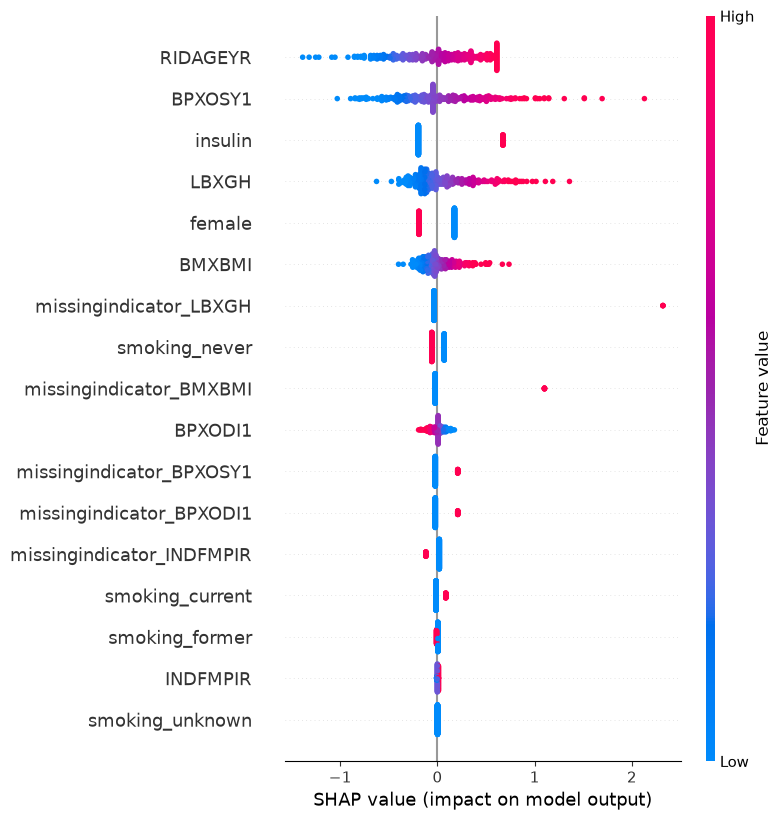

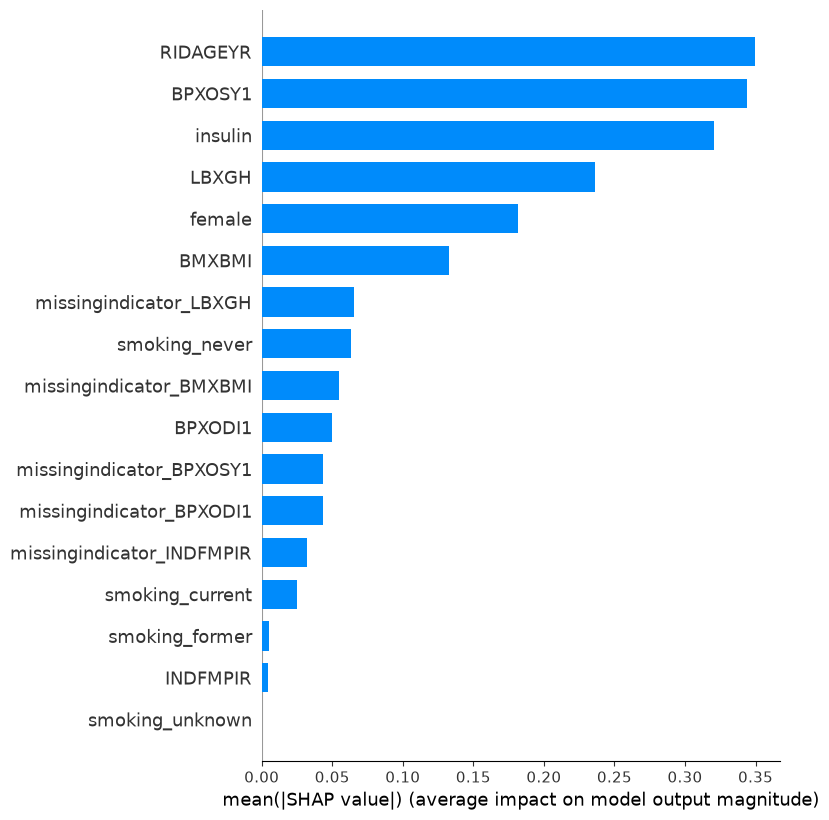

In [14]:
shap.summary_plot(vals, Xte_t, feature_names=names, show=False)
plt.tight_layout(); plt.savefig("../reports/figures/shap_summary.png", dpi=150); plt.show()

shap.summary_plot(vals, Xte_t, feature_names=names, plot_type="bar", show=False)
plt.tight_layout(); plt.savefig("../reports/figures/shap_bar.png", dpi=150); plt.show()

highest predicted probability: 0.988 | true label: 1


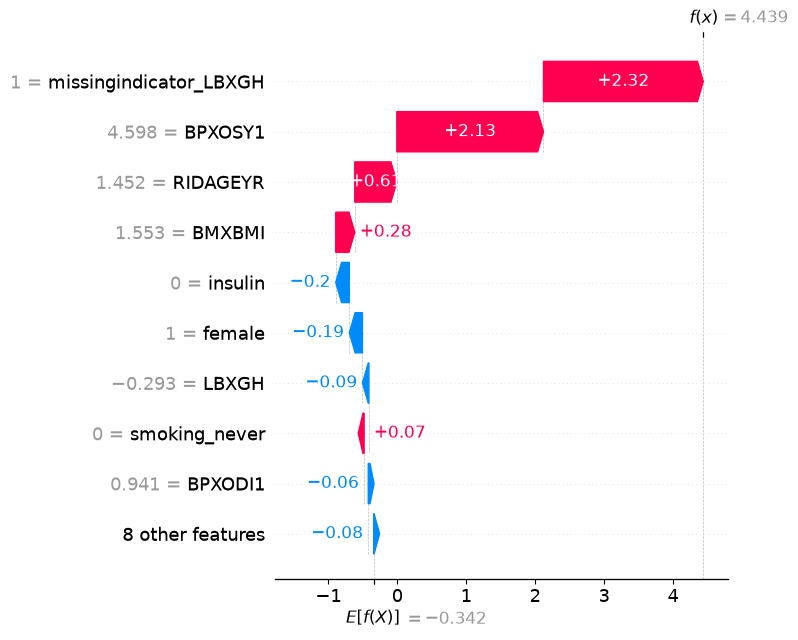

lowest predicted probability: 0.057 | true label: 1


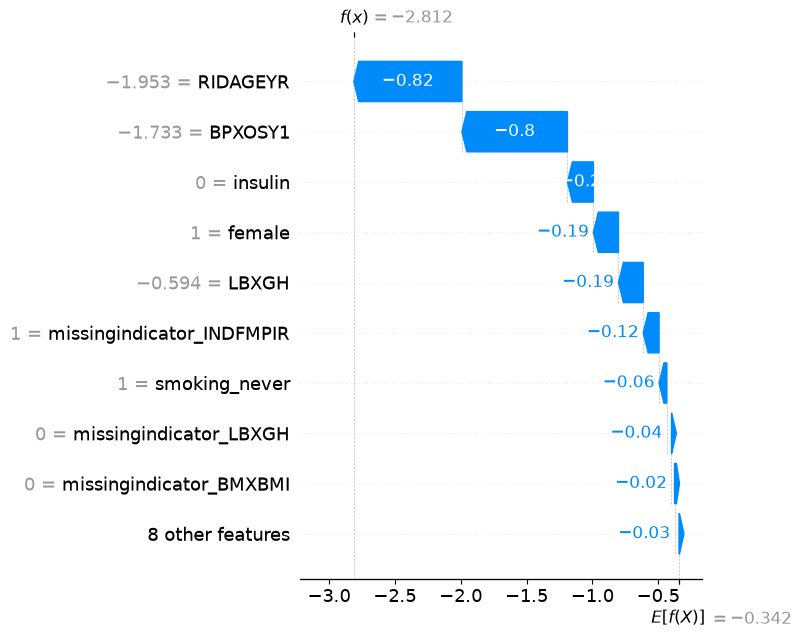

In [15]:
p = pipe.predict_proba(Xte)[:, 1]
for label, i in [("highest", int(np.argmax(p))), ("lowest", int(np.argmin(p)))]:
    print(label, "predicted probability:", round(p[i], 3), "| true label:", yte.iloc[i])
    shap.plots.waterfall(shap.Explanation(values=vals[i], base_values=explainer.expected_value,
                         data=Xte_t[i], feature_names=names), show=False)
    plt.tight_layout(); plt.savefig(f"../reports/figures/shap_waterfall_{label}.png", dpi=150); plt.show()

### Interpretation (SHAP, logistic regression, corrected preprocessing)
Mean |SHAP| on the test set (n = 312), in log-odds units:

| Rank | Feature | Mean abs SHAP |
|---|---|---|
| 1 | Age | 0.350 |
| 2 | Systolic BP | 0.344 |
| 3 | Insulin use | 0.320 |
| 4 | HbA1c | 0.236 |
| 5 | Female sex | 0.182 |
| 6 | BMI | 0.133 |
| 7+ | All others (missing-indicator flags, smoking, diastolic BP, income) | < 0.07 each |

Older age, higher systolic blood pressure, higher HbA1c, higher BMI and insulin use increased the model's score, and female sex decreased it. These are statistical associations learned by the model, not causal effects. Age is inside the eGFR equation, so part of its importance is mechanical. Insulin use may partly reflect reduced kidney function (clinicians avoid some oral agents), so its high rank should be read with the reverse-causation caveat and the sensitivity analysis (removing insulin lowered ROC-AUC by about 0.015). HbA1c also helps define cohort membership. The missing-indicator flags contribute little overall (≤ 0.065), and the few large individual contributions come from rare participants with missing HbA1c or BMI, so they are not interpreted. An earlier SHAP run had wrongly standardised these flags and produced an implausible contribution of +5.8 for one participant; this was detected through SHAP diagnostics and corrected (see the preprocessing correction note). Individual explanations show how each feature moved one participant's score from the baseline (E[f(X)] = −0.34 log-odds), and they describe the model, not the participant's physiology.

Saving to: D:\kidney-disease-analytics\reports\figures


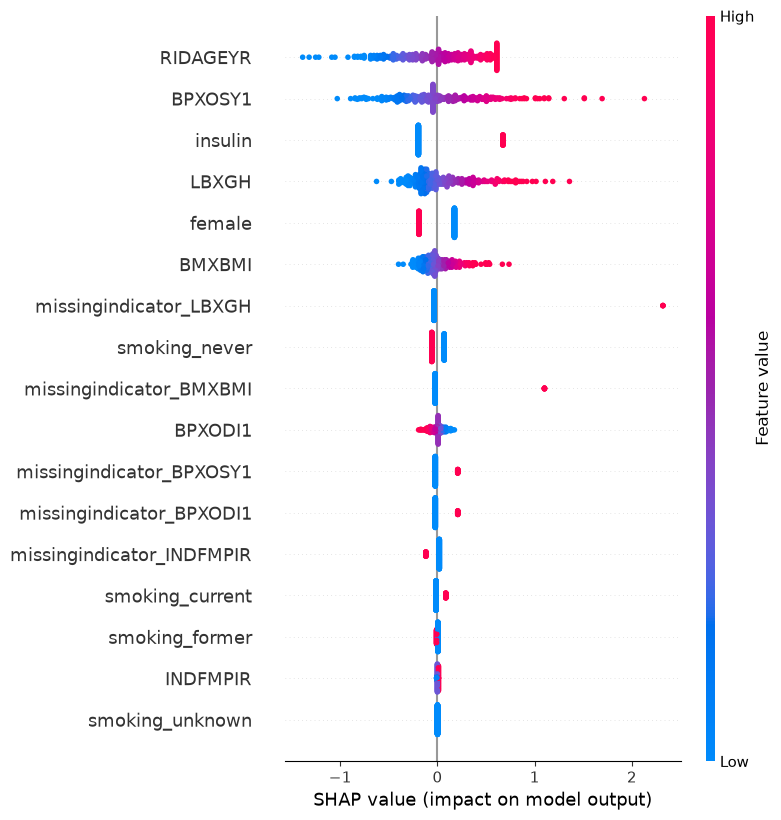

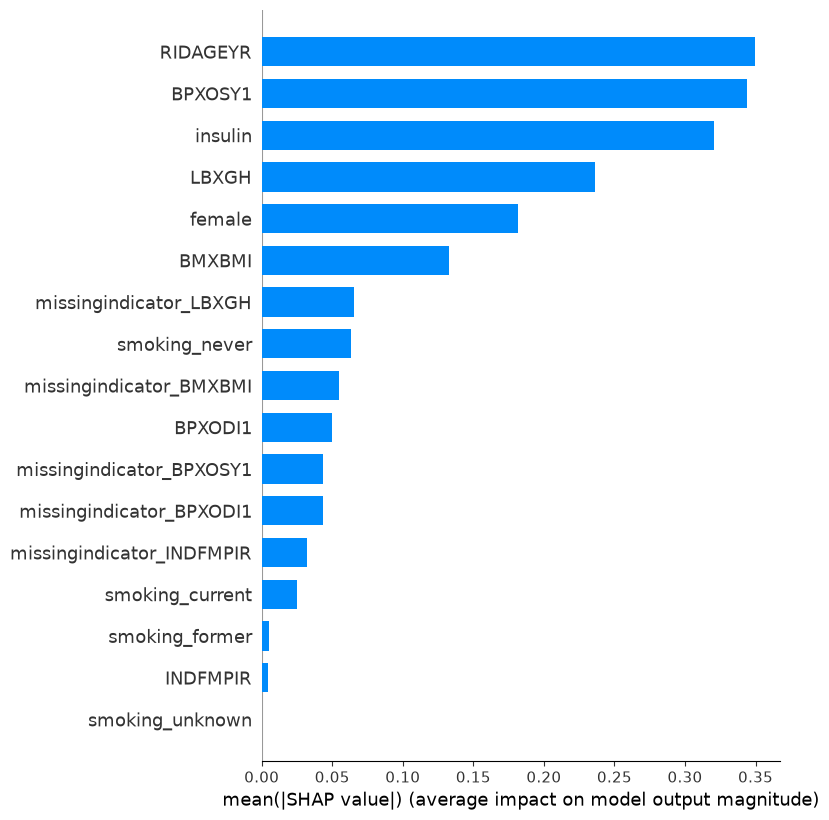

highest predicted probability: 0.988 | true label: 1


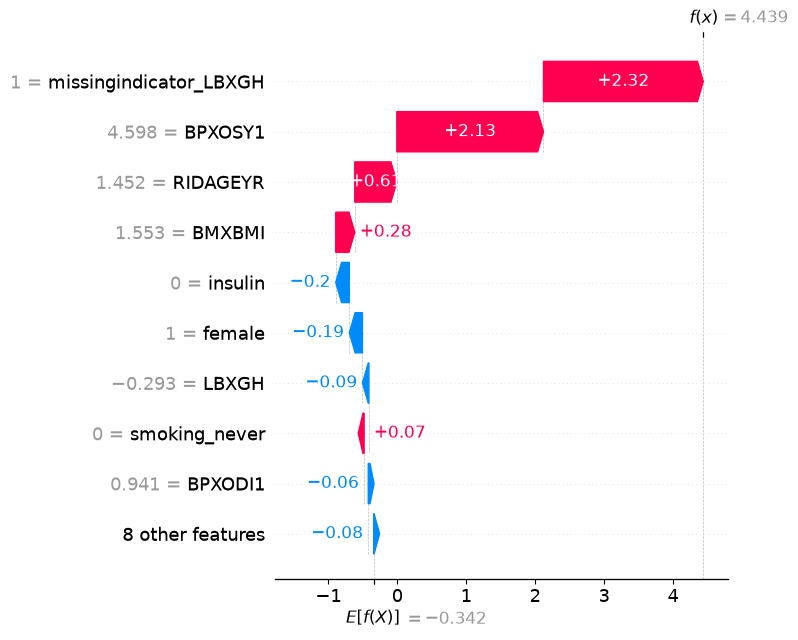

lowest predicted probability: 0.057 | true label: 1


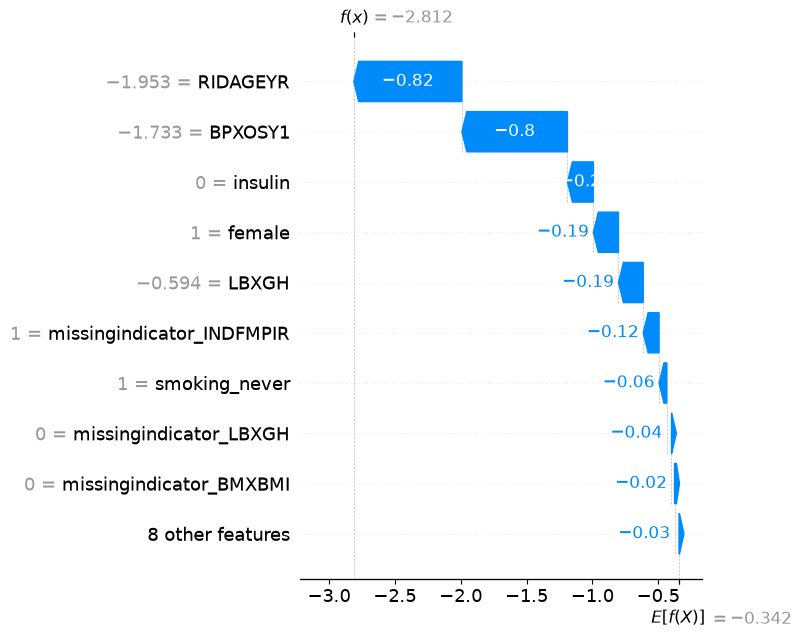

eda_numeric_by_outcome.png
oof_roc_pr.png
shap_bar.png
shap_summary.png
shap_waterfall_highest.png
shap_waterfall_lowest.png
test_confusion_roc.png


In [17]:
import os
from pathlib import Path

fig_dir = Path("../reports/figures").resolve()
fig_dir.mkdir(parents=True, exist_ok=True)
print("Saving to:", fig_dir)

# 1. Summary (beeswarm) plot
shap.summary_plot(vals, Xte_t, feature_names=names, show=False)
plt.tight_layout(); plt.savefig(fig_dir / "shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

# 2. Bar plot
shap.summary_plot(vals, Xte_t, feature_names=names, plot_type="bar", show=False)
plt.tight_layout(); plt.savefig(fig_dir / "shap_bar.png", dpi=150, bbox_inches="tight"); plt.show()

# 3. Waterfalls for the highest and lowest predicted participants
p = pipe.predict_proba(Xte)[:, 1]
for label, i in [("highest", int(np.argmax(p))), ("lowest", int(np.argmin(p)))]:
    print(label, "predicted probability:", round(p[i], 3), "| true label:", yte.iloc[i])
    shap.plots.waterfall(shap.Explanation(values=vals[i], base_values=explainer.expected_value,
                         data=Xte_t[i], feature_names=names), show=False)
    plt.tight_layout(); plt.savefig(fig_dir / f"shap_waterfall_{label}.png", dpi=150, bbox_inches="tight"); plt.show()

# Confirm the files exist
for f in sorted(os.listdir(fig_dir)):
    print(f)

## 8. Save the fitted primary model for the dashboard

**Purpose:** Persist the final logistic regression pipeline (corrected preprocessor, fitted on the training set only) so the Streamlit prototype can load it without access to the data.
**Method:** `joblib.dump` of the full pipeline, plus the training-set background used for SHAP.
**Risk:** The saved file is tied to the library versions used here (Python 3.14.8, scikit-learn 1.9.1), so the app must run in the same `.venv`.

In [18]:
import joblib
from pathlib import Path

app_dir = Path("../app").resolve()
app_dir.mkdir(exist_ok=True)

joblib.dump(pipe, app_dir / "model.joblib")
joblib.dump(Xtr_t, app_dir / "shap_background.joblib")   # transformed training data for SHAP
print("Saved:", sorted(f.name for f in app_dir.iterdir()))

Saved: ['model.joblib', 'shap_background.joblib']
